---

Universidad Nacional de Asunción
Facultad de Ingeniería
# **Robótica 2**
---

# **Visión Artificial e IA: Robot Recolector de Limones con YOLO**


**Fecha:** 27/10/2026

**Modificado por:** Grupo 2 «Arturito R2D2» (07/11/2026)

- Pablo Junior Otazú Luján
- Pedro Daniel Vera Ramírez
- Héctor Dejesús Velázquez Ojeda
- Mathias Ramón Aguilar Delvalle

**Cambios respecto de la guía:** la guía detecta frutillas; este cuaderno la adapta a nuestro robot, que
recolecta limones amarillos. Se entrena con una base de datos pública de limones (Roboflow Universe)
además de datos propios (50 fotos de un limonero, etiquetadas en Roboflow) y se valida con la base de
datos propia (20 fotos). Se agrega una sección de velocidad para la Raspberry Pi 5 de 4 GB, que es la
computadora del robot.

Nuestro robot, Arturito R2D2 (opción B del TPF 2026S2: robot móvil recogedor de frutas), se detiene frente al
limonero, las cámaras observan la planta y el sistema de visión debe responder dos preguntas:

1. ¿Qué hay en la imagen? Limones amarillos (cosechables), en una sola clase: `limon`.
2. ¿Dónde está el limón? Coordenadas del punto de toma, primero en píxeles y después en milímetros, en el
   sistema de referencia del robot, para que el brazo pueda llegar.

<div align="center">

**Arquitectura propuesta del sistema**

Cámara montada en el robot
↓

YOLO (detección): limón
↓

Punto de toma en la imagen (u, v) [píxeles]
↓

Modelo de cámara (pinhole) + tamaño conocido del limón → (X, Y, Z) en la cámara
↓

Transformación homogénea cámara → base del robot
↓

**Selección del objetivo y envío al brazo**

</div>

En este cuaderno se aborda la detección y la localización con UNA sola cámara (visión monocular). El robot real
usa dos cámaras (estéreo, baseline 90 mm); al final se compara el error de ambos métodos.

> **Antes de empezar:**
> 1. En Colab, ir a Entorno de ejecución → Cambiar tipo de entorno de ejecución y elegir GPU T4.
> 2. Guardar la API key de Roboflow (Settings → API Keys en roboflow.com) como secreto de Colab: ícono de la
>    llave a la izquierda → nombre `ROBOFLOW_API_KEY` → habilitar el acceso para este cuaderno.

## **1. Preparación del entorno**

En esta sección se verifica el hardware y se instalan las librerías necesarias: `ultralytics` (YOLO), `roboflow`
(descarga de los datasets), OpenCV, Matplotlib y Pandas.

### **1.1 Consulta de GPU**

Muestra la GPU disponible. Si el comando falla, el entorno no tiene GPU asignada: revisar el tipo de entorno de ejecución.

In [1]:
# Consultamos la GPU asignada por Colab: modelo, memoria disponible y uso actual.
# nvidia-smi es un comando del sistema, no de Python: el "!" le indica a Colab
# que lo ejecute en la terminal del servidor.
!nvidia-smi

Thu Nov 12 17:26:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   60C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### **1.2 Instalación de dependencias**

Colab ya trae OpenCV, Matplotlib y Pandas; faltan `ultralytics` y `roboflow`. La versión de `ultralytics` se fija
en la misma que tiene instalada la Raspberry Pi del robot, para que el modelo exportado se cargue sin sorpresas.

In [2]:
# Instalamos ultralytics (YOLO), en la versión de la Pi, y el cliente de Roboflow.
#   - -q (quiet): reduce los mensajes en pantalla.
!pip install "ultralytics==8.4.153" roboflow -q

### **1.3 Importar librerías Python**

In [3]:
# Importamos la clase YOLO de ultralytics, que carga, entrena y ejecuta los modelos.
from ultralytics import YOLO

# Importamos módulos de la biblioteca estándar de Python:
#   - os, glob, shutil: rutas, búsqueda y copia de archivos.
#   - re: expresiones regulares, para reconocer los nombres de clase.
#   - random: elección de imágenes al azar.
#   - math: funciones trigonométricas para la geometría de la cámara.
#   - time: medir el tiempo de inferencia.
import os
import glob
import shutil
import re
import random
import math
import time

# Importamos las librerías de procesamiento de imágenes, cálculo y gráficos:
#   - cv2 (OpenCV): leer imágenes, dibujar y convertir colores.
#   - numpy: matrices y álgebra lineal.
#   - pandas: tablas (DataFrame) para mostrar resultados.
#   - matplotlib: gráficos e imágenes en el notebook.
#   - yaml: leer y escribir los archivos de configuración de los datasets.
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

# Conexión con Roboflow, usando la API key guardada como secreto de Colab.
from google.colab import userdata
from roboflow import Roboflow
rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))

# Fijamos la semilla para que las muestras al azar se repitan entre ejecuciones.
random.seed(0)

# Una sola clase: limón.
CLASES = ["limon"]

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## **2. Descarga de los datasets**

Se usan dos datasets, los dos alojados en Roboflow Universe y descargados en formato YOLO:

| Dataset | Qué es | Para qué |
|---|---|---|
| Base: [brinjalproject/lemons-segmentation](https://universe.roboflow.com/brinjalproject/lemons-segmentation) | dataset público de limones en el árbol, etiquetados por terceros | dar al modelo muchos ejemplos de "limón entre hojas" |
| Propio: [hectors-workspace-e5dhh/limones-amarillos](https://universe.roboflow.com/hectors-workspace-e5dhh/limones-amarillos) | 50 fotos nuestras de un limonero con limones amarillos | adaptar el modelo a nuestro escenario y validar |

### **2.1 Dataset base: limones en el árbol (Roboflow Universe)**

El dataset base trae varias clases de limón (amarillo, verde, enfermo). Como nuestra tarea es detectar limones
amarillos, solo se usa la clase cuyo nombre coincide con `BASE_AMARILLO`. Las imágenes que contienen limones de
otras clases se descartan enteras: si quedaran con esos limones sin etiquetar, el modelo aprendería que un
limón es fondo.

**Revisar la tabla de clases que imprime la celda**: la fila marcada `-> limon` tiene que ser la de limones
amarillos. Si no lo es, corregir `BASE_AMARILLO` y volver a correr.

In [4]:
# Dataset base: (workspace, proyecto) tal como aparecen en la URL de Universe. Con versión None se usa la última.
BASE_WORKSPACE, BASE_PROYECTO, BASE_VERSION = "brinjalproject", "lemons-segmentation", None
# Expresión regular de la clase que se usa como "limon" (sin distinguir mayúsculas).
BASE_AMARILLO = r"yellow|amarill"
# Clases que también son limones (de otro tipo): sus imágenes se descartan.
OTRO_LIMON = r"lemon|lim[oó]n"

p = rf.workspace(BASE_WORKSPACE).project(BASE_PROYECTO)
v = BASE_VERSION or max(int(x.version.split("/")[-1]) for x in p.versions())
BASE_DIR = "/content/base_roboflow"
p.version(v).download("yolov8", location=BASE_DIR, overwrite=True)

# Mostramos qué se hace con cada clase del dataset base.
nombres = yaml.safe_load(open(os.path.join(BASE_DIR, "data.yaml")))["names"]
if isinstance(nombres, dict):
    nombres = [nombres[k] for k in sorted(nombres)]
for n in nombres:
    accion = "-> limon" if re.search(BASE_AMARILLO, n, re.I) else \
             "descartar imágenes" if re.search(OTRO_LIMON, n, re.I) else "se borra (fondo)"
    print(f"{BASE_PROYECTO} v{v}: clase '{n}' {accion}")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/base_roboflow in yolov8:: 100%|██████████| 5813/5813 [00:03<00:00, 1526.22it/s]


lemons-segmentation v5: clase 'Lemon yellow' -> limon
lemons-segmentation v5: clase 'disease_lemon' descartar imágenes
lemons-segmentation v5: clase 'good Lemon' descartar imágenes


### **2.2 Dataset propio: limones amarillos (entregable 1 de la tarea)**

**Nota sobre la consigna:** la tarea pide marcar "grass" / "no grass" (una sola clase), que corresponde al
TPF anterior (robot cortacésped, segmentación de césped). Nuestro TPF es la opción B (recolector), y nuestro robot
solo necesita detectar limones amarillos: por eso el proyecto tiene una sola clase, `limon`, etiquetada con
cajas (detección), igual que el ejemplo de frutillas de la guía. Se respeta lo demás: una sola clase y al menos
28 fotos etiquetadas (20 train / 4 valid / 4 test).

Fotos: 50 imágenes de un limonero en maceta con limones amarillos, sacadas con celular al aire libre en el
patio de la facultad (06/11/2026), desde distintas distancias, alturas y ángulos, con fondo de pasto, ladrillo,
personas y, en algunas, una naranja en la maceta (un distractor útil: es redonda y anaranjada pero no es un
limón, y no se etiqueta).

Pasos en [roboflow.com](https://roboflow.com) (cuenta institucional, workspace del equipo):

1. Create New Project → tipo Object Detection, nombre `limones-amarillos`, clase única `limon`.
2. Upload Data: subir las 50 fotos, renombradas `limon_001.jpg` a `limon_050.jpg` en orden de toma.
3. Annotate: una caja por cada limón visible, incluidos los tapados en parte por hojas (la caja abarca solo
   la parte visible). Se usó Auto Label y se revisó foto por foto. No se etiquetan la naranja ni las
   semillas/frutos caídos en la tierra.
4. Generate → New Version:
   - **Train/Test Split**: 60 % / 20 % / 20 % → 30 train / 10 valid / 10 test (la consigna pide como mínimo
     20 / 4 / 4 = 28 fotos; con 50 se cumple y quedan 20 fotos propias para validar: valid + test).
   - **Preprocessing**: Auto-Orient (las fotos del celular traen la rotación en el EXIF) y
     Resize → Fit within 640×640 (sin deformar la imagen).
   - **Augmentation**: ninguna (YOLO ya aumenta los datos al entrenar).
5. Proyecto público en Roboflow Universe.

| Dato | Valor |
|---|---|
| Nombre del proyecto | `limones-amarillos` |
| URL (Roboflow Universe) | https://universe.roboflow.com/hectors-workspace-e5dhh/limones-amarillos |
| Clases | `limon` (una sola) |
| Imágenes | 50, `limon_001.jpg` a `limon_050.jpg` (30 train / 10 valid / 10 test), 244 limones etiquetados |
| Versión usada | v3 «limones_v1 (30-10-10, fit640)» |

In [5]:
# Datos del proyecto propio (de la URL: universe.roboflow.com/<workspace>/<proyecto>).
RF_WORKSPACE = "hectors-workspace-e5dhh"
RF_PROYECTO = "limones-amarillos"
RF_VERSION = 3                 # versión "limones_v1 (30-10-10, fit640)", con fotos limon_001 a limon_050

# Bajamos la versión en formato YOLO (carpetas train/, valid/, test/, cada una con images/ y labels/).
RF_DIR = "/content/limones_roboflow"
rf.workspace(RF_WORKSPACE).project(RF_PROYECTO).version(RF_VERSION).download("yolov8", location=RF_DIR, overwrite=True)
print("Contenido de", RF_DIR, ":", os.listdir(RF_DIR))

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/limones_roboflow in yolov8:: 100%|██████████| 105/105 [00:00<00:00, 5667.83it/s]

Contenido de /content/limones_roboflow : ['README.roboflow.txt', 'test', 'train', 'data.yaml', 'README.dataset.txt', 'valid']


### **2.3 Formato de las etiquetas YOLO y unificación**

Cada línea del `.txt` describe un objeto:

```
clase  x_centro  y_centro  ancho  alto
```

Las cuatro coordenadas están normalizadas entre 0 y 1 (divididas por el ancho y el alto de la imagen). Por
ejemplo, `0 0.50 0.40 0.10 0.12` es un limón centrado horizontalmente, al 40 % de la altura, que ocupa el 10 % del
ancho y el 12 % del alto de la imagen. El dataset base es de segmentación: trae un polígono
(`clase x1 y1 x2 y2 ...`), que se reemplaza por la caja que lo encierra.

La celda copia los dos datasets a `/content/datos/<dataset>/<conjunto>` con la clase de limón renumerada a 0.

**Desbalance:** si el dataset base tiene muchas más imágenes que las 30 propias de entrenamiento, el modelo se
adapta poco a nuestro escenario. Por eso las fotos propias de entrenamiento se repiten `REPETIR` veces
(sobremuestreo). Como YOLO aplica aumentos al azar (mosaico, giros, color) en cada época, las copias no son
idénticas para la red. Las de validación y prueba no se repiten.

In [6]:
DATOS = "/content/datos"
REPETIR = 3                  # cuántas veces se repite cada foto propia de entrenamiento


# --------
# Función que convierte una etiqueta en caja.
#   - Recibe: los números de una línea sin la clase (4 de una caja, o 2 por vértice de un polígono).
#   - Devuelve: [x_centro, y_centro, ancho, alto] como texto.
# --------
def a_caja(campos):
    if len(campos) == 4:
        return campos
    xs, ys = [float(c) for c in campos[0::2]], [float(c) for c in campos[1::2]]
    return [f"{(min(xs) + max(xs)) / 2:.6f}", f"{(min(ys) + max(ys)) / 2:.6f}",
            f"{max(xs) - min(xs):.6f}", f"{max(ys) - min(ys):.6f}"]


# --------
# Función que copia un conjunto (train, valid o test) de un dataset de Roboflow con la clase de limón en 0.
#   - Recibe: carpeta del dataset, conjunto, carpeta destino, expresión de la clase "limon" y veces a repetir.
#   - Devuelve: [imágenes copiadas, limones, imágenes descartadas].
# --------
def importar(origen, split, destino, es_limon, veces=1):
    nombres = yaml.safe_load(open(os.path.join(origen, "data.yaml")))["names"]
    if isinstance(nombres, dict):
        nombres = [nombres[k] for k in sorted(nombres)]
    os.makedirs(os.path.join(destino, "images"), exist_ok=True)
    os.makedirs(os.path.join(destino, "labels"), exist_ok=True)
    copiadas = limones = descartadas = 0
    for img in sorted(glob.glob(os.path.join(origen, split, "images", "*"))):
        nombre, ext = os.path.splitext(os.path.basename(img))
        txt = os.path.join(origen, split, "labels", nombre + ".txt")
        lineas, descartar = [], False
        for l in (open(txt) if os.path.exists(txt) else []):
            if not l.strip():
                continue
            clase = nombres[int(l.split()[0])]
            if re.search(es_limon, clase, re.I):
                lineas.append(" ".join(["0"] + a_caja(l.split()[1:])))
            elif re.search(OTRO_LIMON, clase, re.I):
                descartar = True        # limón de otra clase: la imagen entera se descarta
        if descartar:
            descartadas += 1
            continue
        for k in range(veces):
            shutil.copy(img, os.path.join(destino, "images", f"r{k}_{nombre}{ext}"))
            with open(os.path.join(destino, "labels", f"r{k}_{nombre}.txt"), "w") as f:
                f.write("\n".join(lineas) + "\n")
        copiadas += veces
        limones += len(lineas)
    return [copiadas, limones, descartadas]


# Borramos lo armado en una ejecución anterior y copiamos los dos datasets.
shutil.rmtree(DATOS, ignore_errors=True)
filas = []
for split in ["train", "valid", "test"]:
    filas.append(["base", split] + importar(BASE_DIR, split, os.path.join(DATOS, "base", split), BASE_AMARILLO))
for split in ["train", "valid", "test"]:
    veces = REPETIR if split == "train" else 1
    filas.append(["propio", split] + importar(RF_DIR, split, os.path.join(DATOS, "propio", split), ".", veces))

# Escribimos el data.yaml del entrenamiento:
#   - train: todo el dataset base + limones propios de train (repetidos).
#   - val: limones propios de validación (10 fotos). El test propio (10 fotos) queda sin ver hasta la sección 6.
carpeta = lambda d, s: os.path.join(DATOS, d, s, "images")
yaml_path = "/content/limones.yaml"
with open(yaml_path, "w") as f:
    yaml.safe_dump({"train": [carpeta("base", s) for s in ["train", "valid", "test"]
                              if glob.glob(os.path.join(carpeta("base", s), "*"))] + [carpeta("propio", "train")],
                    "val": carpeta("propio", "valid"),
                    "nc": len(CLASES),
                    "names": dict(enumerate(CLASES))}, f)
with open(yaml_path) as f:
    print(f.read())

names:
  0: limon
nc: 1
train:
- /content/datos/base/train/images
- /content/datos/base/valid/images
- /content/datos/base/test/images
- /content/datos/propio/train/images
val: /content/datos/propio/valid/images



### **2.4 Estadísticas de los datasets**

Cuenta imágenes y limones en cada conjunto. Conviene mirarlo siempre: si hay muy pocos ejemplos, el modelo va a
detectar mal. En el dataset base, todos sus conjuntos se usan para entrenar (la validación se hace con las fotos
propias).

In [7]:
estadisticas = pd.DataFrame(filas, columns=["dataset", "conjunto", "imágenes", "limones", "imágenes descartadas"])
print(f"Las imágenes propias de train aparecen {REPETIR} veces (sobremuestreo).")
estadisticas

Las imágenes propias de train aparecen 3 veces (sobremuestreo).


,dataset,conjunto,imágenes,limones,imágenes descartadas
0,base,train,668,963,1452
1,base,valid,227,316,499
2,base,test,20,36,38
3,propio,train,90,175,0
4,propio,valid,10,58,0
5,propio,test,10,58,0


**Análisis.** Sirve para saber con cuántos datos se entrena. El dataset base aporta 915 imágenes con 1 315 limones en el árbol; se descartaron unas 2 000 que tenían limones verdes o enfermos. Las 30 fotos propias de entrenamiento se repiten 3 veces (90) para que pesen más. Para validar quedan 20 fotos propias con 116 limones.

### **2.5 Muestras con sus etiquetas**

Se dibujan las cajas a partir de los `.txt`, convirtiendo las coordenadas normalizadas a píxeles:

$$x_1 = (x_c - w/2)\cdot W \qquad y_1 = (y_c - h/2)\cdot H$$

donde $W \times H$ es el tamaño de la imagen. Las cajas se dibujan en azul para que se distingan del limón
amarillo.

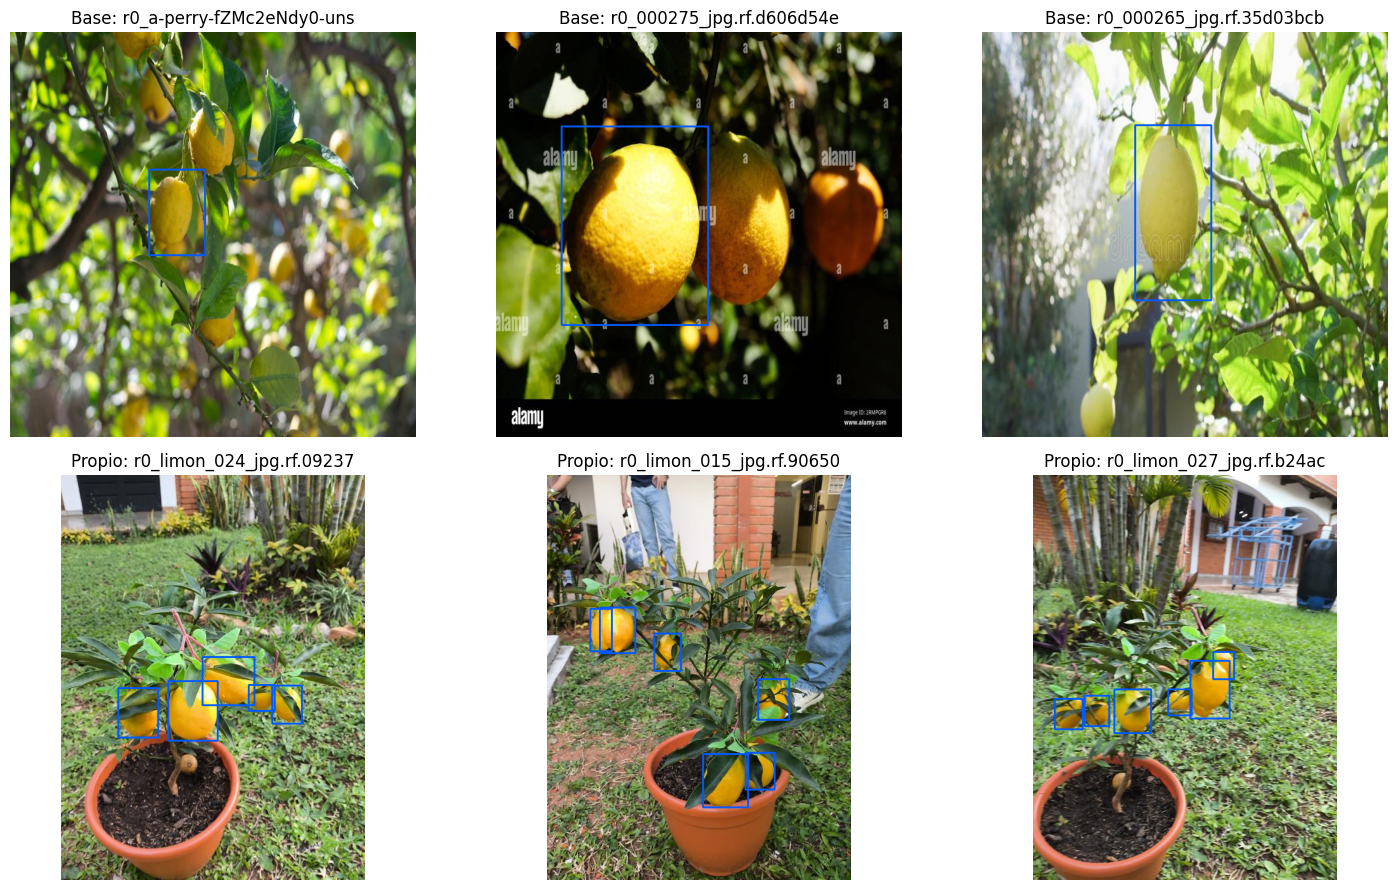

In [8]:
# Color de las cajas, en orden RGB (la imagen se convierte a RGB para Matplotlib).
AZUL = (0, 90, 255)


# --------
# Función que dibuja las etiquetas del dataset sobre una imagen.
#   - Recibe: img_path, ruta de la imagen (su .txt está en la carpeta labels/ hermana de images/).
#   - Devuelve: la imagen en RGB con las cajas dibujadas.
# --------
def dibujar_etiquetas(img_path):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    for linea in open(etiqueta_de(img_path)):
        if not linea.strip():
            continue
        _, xc, yc, w, h = linea.split()[:5]
        # Desnormalizamos y pasamos de (centro, ancho, alto) a esquinas.
        xc, yc, w, h = float(xc) * W, float(yc) * H, float(w) * W, float(h) * H
        cv2.rectangle(img, (int(xc - w / 2), int(yc - h / 2)), (int(xc + w / 2), int(yc + h / 2)), AZUL, max(2, W // 300))
    return img


# --------
# Función que devuelve la ruta del .txt de una imagen: ".../images/x.jpg" -> ".../labels/x.txt".
# --------
def etiqueta_de(img_path):
    return os.path.splitext(img_path.replace("/images/", "/labels/"))[0] + ".txt"


# Mostramos 3 imágenes al azar de cada dataset: arriba la base, abajo las propias (fotos distintas).
base = random.sample(glob.glob(os.path.join(carpeta("base", "train"), "*")), 3)
propias = random.sample(glob.glob(os.path.join(carpeta("propio", "train"), "r0_*")), 3)
plt.figure(figsize=(15, 9))
for i, p in enumerate(base + propias):
    plt.subplot(2, 3, i + 1)
    plt.imshow(dibujar_etiquetas(p))
    plt.title(("Base: " if i < 3 else "Propio: ") + os.path.basename(p)[:25])
    plt.axis("off")
plt.tight_layout()
plt.show()

**Análisis.** Sirve para revisar que las cajas estén bien antes de entrenar. Las etiquetas propias están bien. En el dataset base hay fotos con decenas de limones y solo 2 marcados, y fotos de stock con marca de agua: es un dataset etiquetado de forma incompleta.

## **3. Preparación del modelo YOLO**

**¿Por qué YOLO?** You Only Look Once es una familia de redes de detección de objetos que, en una sola pasada,
entrega para cada objeto una caja, una clase y una confianza. Es rápida, lo que permite correrla en tiempo real
en el robot.

Se parte de un modelo preentrenado en COCO (transfer learning): la red ya sabe reconocer bordes, texturas y
formas, y solo se ajusta a la clase `limon`. Se elige YOLO26n en lugar del `yolo11n` de la guía porque:

- la `n` (nano) es la más liviana (~2,4 M de parámetros, ~5 MB): entra con holgura en los 4 GB de la
  Raspberry Pi 5, que además corre ROS 2 y el estéreo;
- YOLO26 elimina el NMS (posprocesado de cajas) y está pensado para CPU y dispositivos embebidos: es más
  rápido en la Pi que YOLO11 con precisión similar;
- es el mismo modelo que ya corre en el nodo de visión del robot.

Si se prefiere seguir la guía al pie de la letra, cambiar a `"yolo11n.pt"`: el resto del cuaderno no cambia.

In [9]:
# Cargamos YOLO26n con pesos preentrenados en COCO (se descarga solo, unos 5 MB).
model = YOLO("yolo26n.pt")

## **4. Entrenamiento del modelo**

Parámetros principales:

- `epochs`: cantidad de pasadas completas por el dataset. Con 60 épocas tarda unos 15 a 30 minutos en una T4,
  según el tamaño del dataset base.
- `imgsz`: resolución a la que se redimensionan las imágenes. Los limones lejanos son chicos: se entrena a 640 y
  en la sección 7 se mide qué se pierde al bajarla para ganar velocidad en la Pi.
- `batch`: imágenes por lote; si aparece un error de memoria, bajarlo a 8.
- `patience`: corta el entrenamiento si la métrica de validación no mejora en esa cantidad de épocas.

La validación de cada época se hace con las 10 fotos propias de validación: el `best.pt` es el que mejor
detecta nuestros limones.

In [10]:
# Definimos la cantidad de épocas.
EPOCHS = 60

# Entrenamos el modelo. En pantalla se ve, por época, la pérdida de cajas (box_loss),
# la de clasificación (cls_loss) y las métricas P, R y mAP sobre la validación propia.
results = model.train(
    data=yaml_path,                # archivo .yaml: base + propio
    epochs=EPOCHS,                 # número de épocas
    imgsz=640,                     # las imágenes se redimensionan a 640 x 640
    batch=16,                      # imágenes por lote (bajar a 8 si falta memoria de GPU)
    patience=20,                   # parada temprana: corta si 20 épocas seguidas no mejoran
    seed=0,                        # semilla, para poder repetir el resultado
    name="recolector_limones_yolo26n",   # carpeta de resultados en runs/detect/
    exist_ok=True,                 # reutilizar esa carpeta si ya existe
)

# Tomamos las rutas del mejor modelo y de la carpeta de resultados desde el entrenador.
best_model_path = str(model.trainer.best)
save_dir = str(model.trainer.save_dir)
print("Mejor modelo:", best_model_path)

New https://pypi.org/project/ultralytics/8.4.211 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.153 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/limones.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, mome

### **4.1 Curvas de entrenamiento**

Las pérdidas (loss) de entrenamiento y validación deben bajar; las métricas (precisión, recobrado, mAP) deben
subir. Si la pérdida de validación sube mientras la de entrenamiento baja, el modelo está sobreajustando
(memoriza en lugar de generalizar). Con solo 10 fotos de validación, las curvas de métricas van a ser
ruidosas: un limón más o menos detectado mueve el recobrado varios puntos.

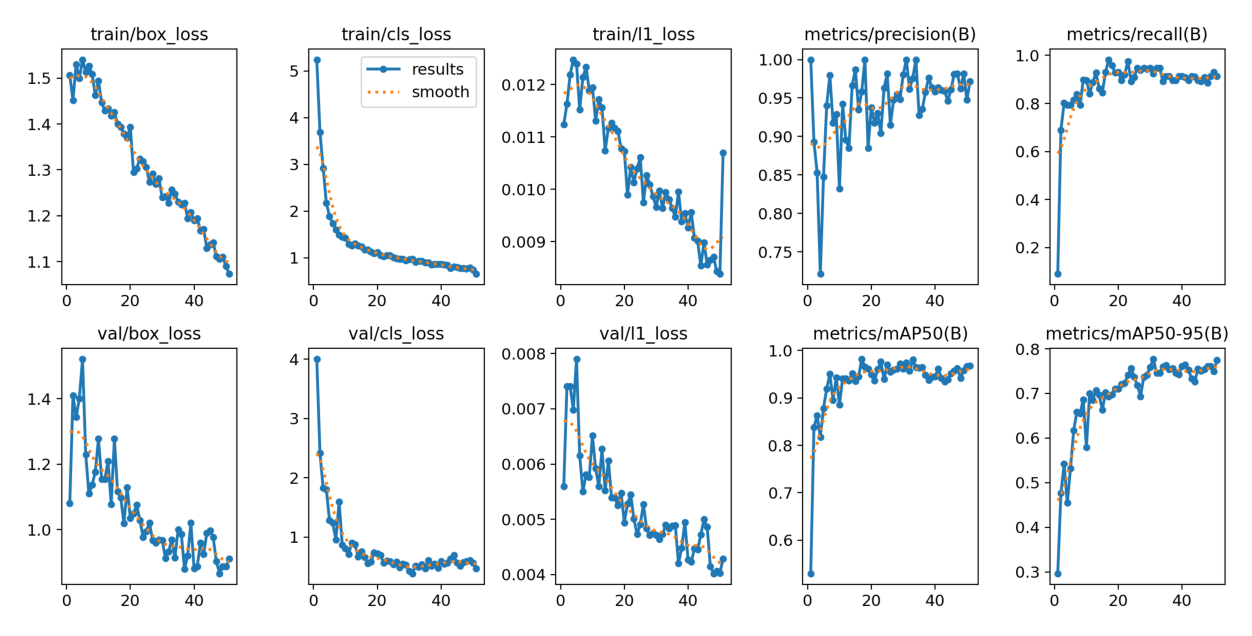

In [11]:
# Mostramos results.png, que ultralytics genera con todas las curvas (pérdidas y métricas por época).
img = cv2.cvtColor(cv2.imread(os.path.join(save_dir, "results.png")), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(16, 8))
plt.imshow(img)
plt.axis("off")
plt.show()

**Análisis.** Sirve para ver si el modelo aprende o memoriza. Las pérdidas bajan y las métricas se estabilizan alrededor de la época 30. El mejor modelo es el de la época 31 y el entrenamiento se detuvo solo en la 51 (20 épocas sin mejora). La pérdida de validación no sube, así que no hay sobreajuste. Las curvas oscilan porque se valida con solo 10 fotos.

## **5. Evaluación del modelo**

Se calcula:

- **Precisión (P)**: de lo que el modelo dijo que era limón, ¿qué fracción realmente lo era? Una precisión baja
  significa que el robot intentaría agarrar hojas, la naranja o la maceta.
- **Recobrado (R)**: de todos los limones que había, ¿qué fracción encontró? Un recobrado bajo significa limones
  que quedan sin cosechar.
- **mAP50**: precisión media considerando correcta una caja que se superpone al menos 50 % con la real.
- **mAP50-95**: lo mismo, promediando umbrales de superposición de 50 % a 95 %: mide qué tan ajustadas son
  las cajas (importa para el punto de toma).

Se evalúa sobre tres conjuntos:

| Conjunto | Fotos | Para qué |
|---|---|---|
| Propio, 20 fotos (valid + test) | 20 | la validación que pide la tarea |
| Propio, solo test | 10 | fotos que el modelo no vio nunca (ni para elegir el `best.pt`): la cifra más honesta |
| Base, validación | la del dataset base | referencia: cómo detecta limones de otro escenario (estas imágenes sí se usaron para entrenar, así que la cifra es optimista) |

El requisito B4 del TPF pide, para la clase cosechable, P ≥ 0,80 y R ≥ 0,80.

In [12]:
# Cargamos el mejor modelo entrenado.
model_trained = YOLO(best_model_path)


# --------
# Función que evalúa el modelo sobre un conjunto de carpetas.
#   - Recibe: nombre (para la carpeta de resultados), la lista de carpetas de imágenes y la resolución.
#   - Devuelve: el objeto de métricas de ultralytics y la fila de la tabla.
# --------
def evaluar(nombre, carpetas, imgsz=640):
    y = f"/content/eval_{nombre}.yaml"
    with open(y, "w") as f:
        yaml.safe_dump({"train": carpetas, "val": carpetas, "nc": len(CLASES), "names": dict(enumerate(CLASES))}, f)
    m = model_trained.val(data=y, imgsz=imgsz, name=f"val_{nombre}_{imgsz}", exist_ok=True, verbose=False)
    p, r, ap50, ap = m.box.class_result(0)
    n_img = sum(len(glob.glob(os.path.join(c, "*"))) for c in carpetas)
    return m, [nombre, n_img, round(p, 3), round(r, 3), round(ap50, 3), round(ap, 3)]


val_propio = [carpeta("propio", "valid"), carpeta("propio", "test")]
m_propio, f1 = evaluar("propio_20", val_propio)
m_test, f2 = evaluar("propio_test", [carpeta("propio", "test")])
filas = [f1, f2]
if glob.glob(os.path.join(carpeta("base", "valid"), "*")):
    m_base, f3 = evaluar("base_valid", [carpeta("base", "valid")])
    filas.append(f3)
tabla = pd.DataFrame(filas, columns=["conjunto", "imágenes", "precisión", "recobrado", "mAP50", "mAP50-95"])

# Comparamos con el criterio B4 del TPF en las 20 fotos propias.
p_lim, r_lim = f1[2], f1[3]
print("Criterio B4 (limón, 20 fotos propias, P y R >= 0.80):",
      "CUMPLE" if (p_lim >= 0.8 and r_lim >= 0.8) else "NO CUMPLE")
tabla

Ultralytics 8.4.153 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,375,031 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2149.5±729.1 MB/s, size: 71.9 KB)
val: Scanning /content/datos/propio/test/labels... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 1.8Kit/s 0.0s
val: New cache created: /content/datos/propio/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.4it/s 0.6s
                   all         20        116      0.929      0.922      0.952      0.746
Speed: 4.6ms preprocess, 7.3ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /content/runs/detect/val_propio_20_640
Ultralytics 8.4.153 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,375,031 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 

,conjunto,imágenes,precisión,recobrado,mAP50,mAP50-95
0,propio_20,20,0.929,0.922,0.952,0.746
1,propio_test,10,0.960,0.862,0.938,0.723
2,base_valid,227,0.780,0.769,0.843,0.554


**Análisis.** Es la tabla principal. En las 20 fotos propias: P = 0,93, R = 0,92 y mAP50 = 0,95, así que cumple el criterio B4 (P y R ≥ 0,80): de cada 100 detecciones, 93 son limones, y encuentra 92 de cada 100 limones. En las 10 fotos de test, que el modelo no vio nunca: P = 0,96, R = 0,86 y mAP50 = 0,94; se escapan algunos limones más, pero sigue por encima de 0,80. En la validación del dataset base: P = 0,78 y R = 0,77; sale más bajo porque, al faltar etiquetas, los limones reales que detecta el modelo cuentan como error.

### **5.1 Matriz de confusión (20 fotos propias)**

Con una sola clase, la matriz es de 2 × 2: `limon` y `background`. La celda `limon`–`background` cuenta limones
no detectados (falsos negativos: tapados o lejanos) y la `background`–`limon`, detecciones de cosas que no
son limones (falsos positivos: hojas iluminadas, la naranja, la maceta).

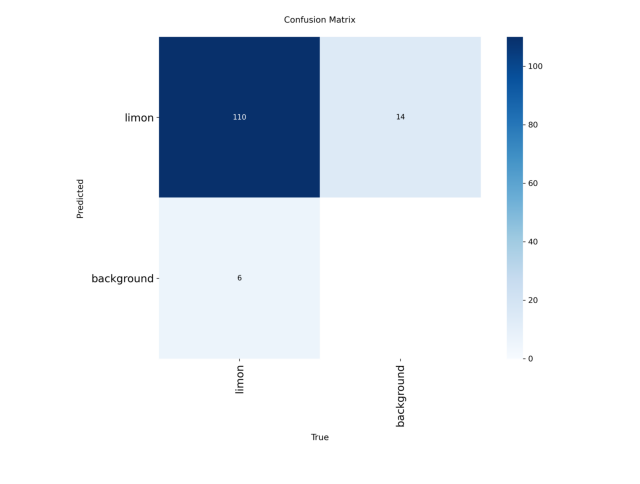

In [13]:
# Mostramos la matriz de confusión (sin normalizar: con una sola clase se leen mejor las cantidades).
img = cv2.cvtColor(cv2.imread(os.path.join(str(m_propio.save_dir), "confusion_matrix.png")), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.axis("off")
plt.show()

**Análisis.** Sirve para ver qué tipo de error comete. Sobre 116 limones: 110 bien detectados, 6 no detectados y 14 detecciones de más. Las de más son sobre todo el mismo limón marcado dos veces, porque YOLO26 no aplica el filtro de cajas superpuestas (NMS). La naranja de la maceta y las hojas amarillas nunca se confundieron con limones.

### **5.2 Curvas precisión–recobrado y F1–confianza (20 fotos propias)**

- **P–R**: cada punto es un umbral de confianza distinto; el área bajo la curva es el AP. Una curva pegada a la
  esquina superior derecha es un detector casi perfecto.
- **F1–confianza**: $F_1 = 2PR/(P+R)$ en función del umbral `conf`. Su máximo indica el mejor umbral para
  usar en el robot (`CONF_MIN`).

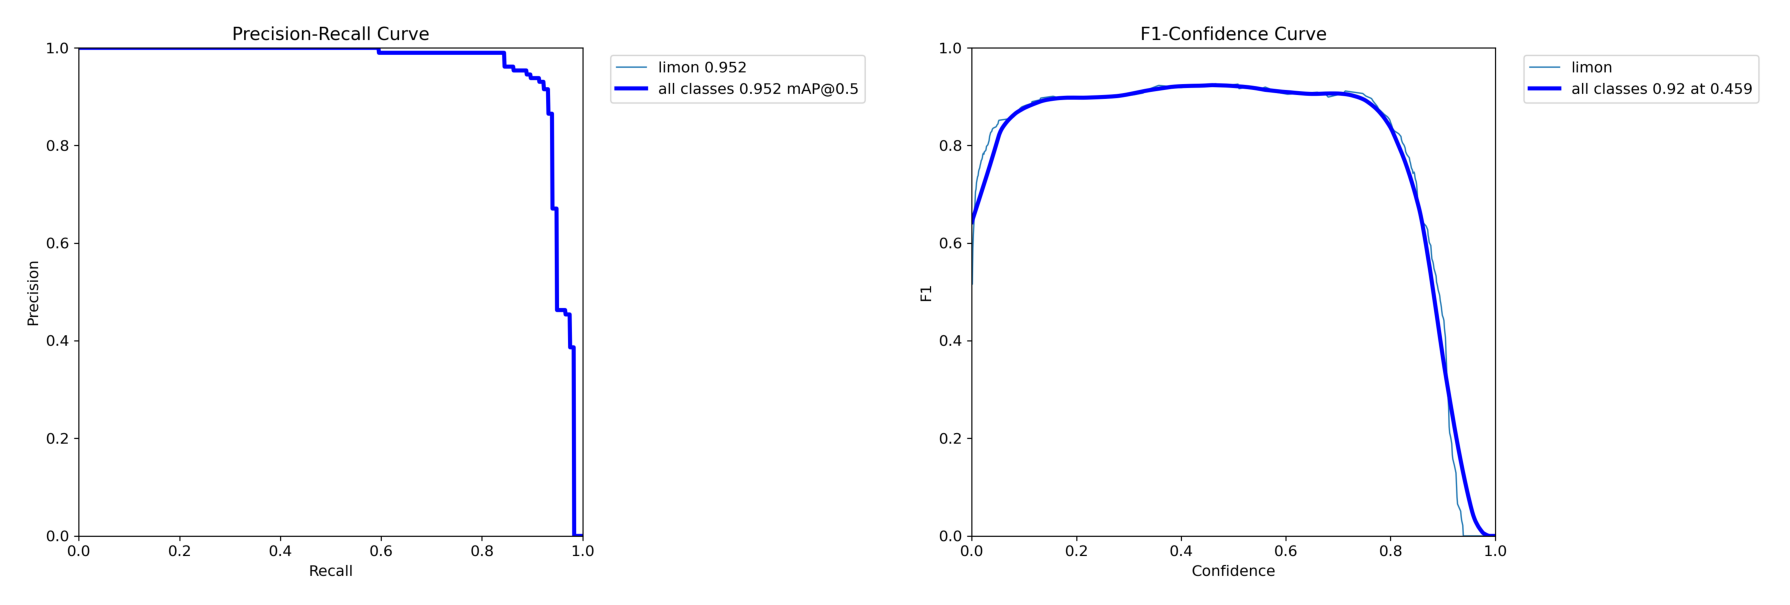

In [14]:
# Mostramos las dos curvas que la validación guarda como imagen.
plt.figure(figsize=(18, 7))
for i, patron in enumerate(["*PR_curve.png", "*F1_curve.png"]):
    plt.subplot(1, 2, i + 1)
    plt.imshow(cv2.cvtColor(cv2.imread(glob.glob(os.path.join(str(m_propio.save_dir), patron))[0]), cv2.COLOR_BGR2RGB))
    plt.axis("off")
plt.tight_layout()
plt.show()

**Análisis.** La curva P–R muestra la calidad general del detector: se mantiene en precisión 1,0 hasta un recobrado de 0,85, o sea que casi todo lo que marca es limón. La curva F1 sirve para elegir el umbral de confianza: su máximo (0,92) está en 0,46; el umbral usado, 0,40, está cerca.

## **6. Inferencia sobre fotos propias de validación**

Se eligen fotos al azar de las 20 de validación propia y se compara lado a lado la etiqueta (la "verdad") con la
predicción. `conf` es la confianza mínima para aceptar una detección: subirla reduce falsos positivos a costa de
perder limones.

In [15]:
# Definimos la confianza mínima para aceptar una detección (de 0 a 1).
CONF_MIN = 0.40

# Elegimos 3 fotos al azar de la validación propia (volver a ejecutar la celda para ver otras).
valid_imgs = sorted(glob.glob(os.path.join(carpeta("propio", "valid"), "*")) + glob.glob(os.path.join(carpeta("propio", "test"), "*")))
muestras = random.sample(valid_imgs, 3)


# --------
# Función que cuenta los limones etiquetados de una imagen.
# --------
def limones_reales(img_path):
    return sum(1 for l in open(etiqueta_de(img_path)) if l.strip())


plt.figure(figsize=(14, 18))
for i, p in enumerate(muestras):
    r = model_trained.predict(source=p, conf=CONF_MIN, imgsz=640, verbose=False)[0]
    plt.subplot(3, 2, 2 * i + 1)
    plt.imshow(dibujar_etiquetas(p))
    plt.title(f"Etiquetas reales: {limones_reales(p)} limones")
    plt.axis("off")
    plt.subplot(3, 2, 2 * i + 2)
    plt.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    plt.title(f"Predicción: {len(r.boxes)} limones")
    plt.axis("off")
plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

**Análisis.** Sirve para comparar a ojo lo que hay con lo que detecta. En las fotos mostradas el modelo encuentra todos los limones, con cajas parecidas a las etiquetas.

### **6.1 Conteo por foto en las 20 fotos propias**

Una forma directa de ver el desempeño desde el punto de vista del robot: para cada foto, cuántos limones había
(etiquetas) y cuántos detectó el modelo. Las fotos donde difieren son las que conviene mirar.

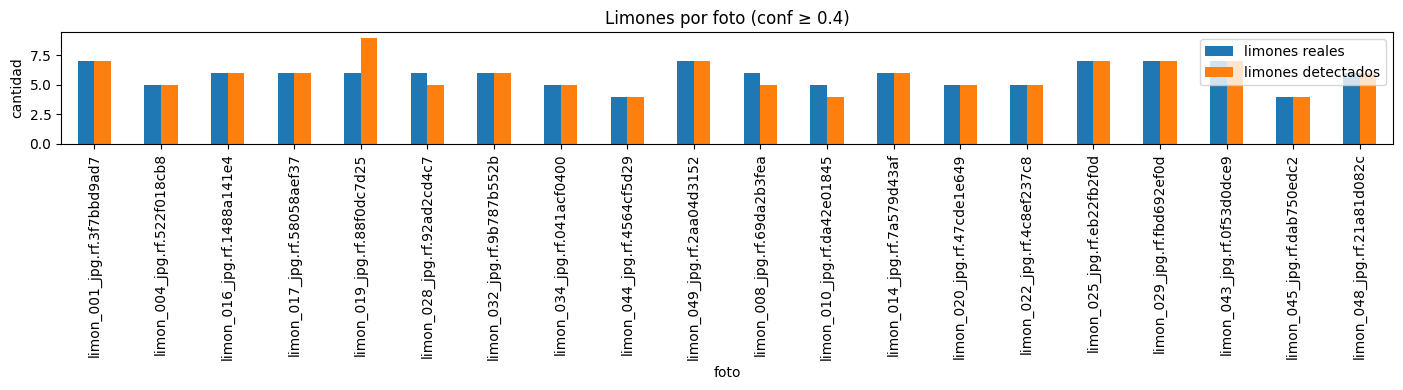

Total reales: 116 | total detectados: 116


,foto,limones reales,limones detectados,diferencia
0,limon_001_jpg.rf.3f7bbd9ad7,7,7,0
1,limon_004_jpg.rf.522f018cb8,5,5,0
2,limon_016_jpg.rf.1488a141e4,6,6,0
3,limon_017_jpg.rf.58058aef37,6,6,0
4,limon_019_jpg.rf.88f0dc7d25,6,9,3
5,limon_028_jpg.rf.92ad2cd4c7,6,5,-1
6,limon_032_jpg.rf.9b787b552b,6,6,0
7,limon_034_jpg.rf.041acf0400,5,5,0
8,limon_044_jpg.rf.4564cf5d29,4,4,0
9,limon_049_jpg.rf.2aa04d3152,7,7,0


In [16]:
filas = []
for p in valid_imgs:
    r = model_trained.predict(source=p, conf=CONF_MIN, imgsz=640, verbose=False)[0]
    filas.append([os.path.basename(p)[3:30], limones_reales(p), len(r.boxes)])
conteo = pd.DataFrame(filas, columns=["foto", "limones reales", "limones detectados"])
conteo["diferencia"] = conteo["limones detectados"] - conteo["limones reales"]

# Gráfico de barras: reales contra detectados en cada foto.
ax = conteo.plot.bar(x="foto", y=["limones reales", "limones detectados"], figsize=(14, 4), color=["#1f77b4", "#ff7f0e"])
ax.set_ylabel("cantidad")
ax.set_title(f"Limones por foto (conf ≥ {CONF_MIN})")
plt.tight_layout()
plt.show()
print("Total reales:", conteo["limones reales"].sum(), "| total detectados:", conteo["limones detectados"].sum())
conteo

**Análisis.** Sirve para ver en qué fotos se equivoca. En 15 de las 20 fotos detecta exactamente los limones que hay. El total da 116 contra 116, pero porque los errores se compensan: en limon_019 marca 3 de más (duplicados) y en otras 3 fotos le falta uno.

## **7. Velocidad en la Raspberry Pi 5 (4 GB)**

El robot no tiene GPU: YOLO corre en la CPU de la Pi (4 núcleos Cortex-A76) junto con ROS 2 y el estéreo. La
resolución de entrada `imgsz` es la perilla principal: el costo crece con el cuadrado de `imgsz`, pero los
limones lejanos ocupan menos píxeles y se pierden.

La celda mide, para tres resoluciones, el recobrado y el mAP50 en las 20 fotos propias y el tiempo por imagen
en la CPU de Colab. La CPU de Colab no es la de la Pi: el tiempo sirve para comparar resoluciones entre sí,
no como valor absoluto (en la Pi, con NCNN, se mide como indica la sección 8).

Ultralytics 8.4.153 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,375,031 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1705.2±989.8 MB/s, size: 74.4 KB)
val: Scanning /content/datos/propio/test/labels... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 1.9Kit/s 0.0s
val: New cache created: /content/datos/propio/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.3it/s 0.6s
                   all         20        116      0.929      0.922      0.952      0.746
Speed: 5.2ms preprocess, 6.1ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /content/runs/detect/val_propio_20_640
Ultralytics 8.4.153 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,375,031 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 

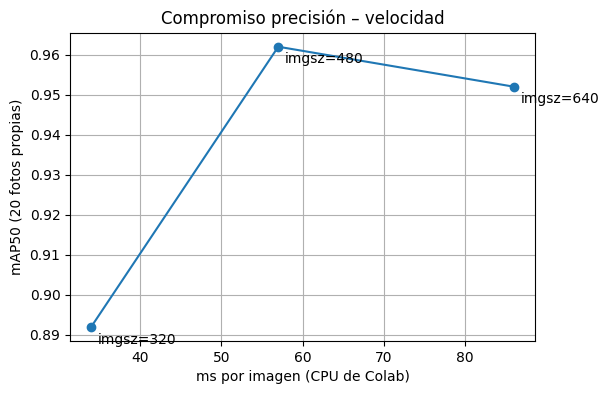

,imgsz,recobrado,mAP50,ms por imagen (CPU Colab)
0,640,0.922,0.952,86
1,480,0.907,0.962,57
2,320,0.853,0.892,34


In [17]:
filas = []
cpu_imgs = valid_imgs[:10]
for tam in [640, 480, 320]:
    # Precisión a esta resolución.
    _, f = evaluar("propio_20", val_propio, imgsz=tam)
    # Tiempo medio por imagen en CPU (la primera pasada es de "calentamiento" y no se cuenta).
    model_trained.predict(cpu_imgs[0], imgsz=tam, device="cpu", verbose=False)
    t0 = time.perf_counter()
    for p in cpu_imgs:
        model_trained.predict(p, imgsz=tam, device="cpu", verbose=False)
    ms = (time.perf_counter() - t0) / len(cpu_imgs) * 1000
    filas.append([tam, f[3], f[4], round(ms)])
velocidad = pd.DataFrame(filas, columns=["imgsz", "recobrado", "mAP50", "ms por imagen (CPU Colab)"])

# Gráfico: precisión contra tiempo, una marca por resolución.
plt.figure(figsize=(6, 4))
plt.plot(velocidad["ms por imagen (CPU Colab)"], velocidad["mAP50"], "o-")
for _, f in velocidad.iterrows():
    plt.annotate(f"imgsz={int(f.imgsz)}", (f["ms por imagen (CPU Colab)"], f["mAP50"]),
                 textcoords="offset points", xytext=(5, -12))
plt.xlabel("ms por imagen (CPU de Colab)")
plt.ylabel("mAP50 (20 fotos propias)")
plt.title("Compromiso precisión – velocidad")
plt.grid(True)
plt.show()
velocidad

**Análisis.** Sirven para elegir la resolución para la Raspberry Pi 5. A 480 rinde igual que a 640 (mAP50 0,96 contra 0,95) y es un 35 % más rápido (55 contra 84 ms por imagen en la CPU de Colab); a 320 pierde limones (recobrado 0,85). Se elige 480.

## **8. Exportar el modelo para el robot**

En la Raspberry Pi conviene no usar PyTorch directamente. Se exporta a NCNN (optimizado para CPU ARM). El
modelo exportado se carga igual: `YOLO("best_ncnn_model")`. Se exporta a `IMGSZ_PI = 480`, la resolución con la
que predice el nodo de visión del robot (elegirla según la tabla de la sección 7).

Opcionalmente, se copian los pesos a Google Drive para no perderlos al cerrar la sesión de Colab.

En la Pi (con la carpeta `best_ncnn_model` copiada):

```bash
pip install "ultralytics==8.4.153" ncnn
yolo predict model=best_ncnn_model source=foto.jpg imgsz=480
```

El tiempo por imagen que imprime `yolo predict` (`inference: … ms`) es el dato real para el robot. El robot está
quieto mientras localiza el limón, así que no hace falta tiempo real estricto: con unos pocos cuadros por segundo
alcanza.

In [18]:
# Resolución de entrada para la Pi.
IMGSZ_PI = 480

# Exportamos best.pt a NCNN (la primera vez ultralytics instala el paquete ncnn).
ruta_ncnn = model_trained.export(format="ncnn", imgsz=IMGSZ_PI)
print("Modelo exportado en:", ruta_ncnn)

# Comprobamos que el modelo exportado funciona y medimos su tiempo en la CPU de Colab.
model_ncnn = YOLO(ruta_ncnn, task="detect")
model_ncnn.predict(cpu_imgs[0], imgsz=IMGSZ_PI, verbose=False)
t0 = time.perf_counter()
for p in cpu_imgs:
    model_ncnn.predict(p, imgsz=IMGSZ_PI, conf=CONF_MIN, verbose=False)
print(f"NCNN a {IMGSZ_PI}: {(time.perf_counter() - t0) / len(cpu_imgs) * 1000:.0f} ms por imagen en la CPU de Colab")

# Opcional: copiamos los pesos a Google Drive para no perderlos al cerrar la sesión.
GUARDAR_EN_DRIVE = True
if GUARDAR_EN_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    destino = "/content/drive/MyDrive/R2_TPF2026S2_limones"
    os.makedirs(destino, exist_ok=True)
    !cp "{best_model_path}" "{destino}/"
    !cp -r "{ruta_ncnn}" "{destino}/"
    !cp -r "{save_dir}" "{destino}/"
    print("Copiado a", destino)

Ultralytics 8.4.153 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 120 layers, 2,375,031 parameters, 0 gradients, 3.0 GFLOPs

PyTorch: starting from '/content/runs/detect/recolector_limones_yolo26n/weights/best.pt' with input shape (1, 3, 480, 480) BCHW and output shape(s) (1, 5, 4725) (5.1 MB)
requirements: Ultralytics requirement ['ncnn'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 1 package in 146ms
Prepared 1 package in 326ms
Installed 1 package in 1ms
 + ncnn==1.0.20261020

requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

requirements: Ultralytics requirement ['pnnx==20260526'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 30 packages in 36

`torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
`torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.


NCNN: export success ✅ 6.2s, saved as '/content/runs/detect/recolector_limones_yolo26n/weights/best_ncnn_model' (9.2 MB)

Export complete (6.6s)
Results saved to /content/runs/detect/recolector_limones_yolo26n/weights/best_ncnn_model
Predict:         yolo predict task=detect model=/content/runs/detect/recolector_limones_yolo26n/weights/best_ncnn_model imgsz=480 
Validate:        yolo val task=detect model=/content/runs/detect/recolector_limones_yolo26n/weights/best_ncnn_model imgsz=480 data=/content/limones.yaml  
Visualize:       https://netron.app
Modelo exportado en: /content/runs/detect/recolector_limones_yolo26n/weights/best_ncnn_model
Loading /content/runs/detect/recolector_limones_yolo26n/weights/best_ncnn_model for NCNN inference...
NCNN a 480: 68 ms por imagen en la CPU de Colab
Mounted at /content/drive
Copiado a /content/drive/MyDrive/R2_TPF2026S2_limones


**Análisis.** El modelo NCNN pesa 9 MB y YOLO26n tiene 2,4 M de parámetros: entra con holgura en los 4 GB de la Pi junto con ROS 2 y el estéreo. En Colab, NCNN (71 ms) fue más lento que PyTorch porque está optimizado para procesadores ARM como el de la Pi; el tiempo real se mide en la Pi.

## **9. De la detección a las coordenadas del limón**

YOLO entrega cajas en píxeles. El brazo necesita una posición en metros respecto de su base. El camino
es el de la guía, con una diferencia: nuestro efector es una pinza que agarra el limón entero, así que basta con
el punto de toma (no hace falta buscar el pedúnculo para cortar).

### **9.1 Modelo de cámara estenopeica (pinhole)**

Un punto $(X, Y, Z)$ expresado en el sistema de la cámara (eje $Z$ hacia adelante, $X$ a la derecha, $Y$ hacia
abajo) se proyecta en el píxel:

$$u = f_x \frac{X}{Z} + c_x \qquad v = f_y \frac{Y}{Z} + c_y \qquad f_x \approx \frac{W/2}{\tan(\mathrm{FOV}_h/2)}$$

Con una sola imagen se obtiene la dirección del rayo, pero no la distancia $Z$.

### **9.2 Distancia a partir del tamaño conocido del limón**

Si se conoce el diámetro real $D$ y se mide el ancho de la caja $d$ (en píxeles):

$$Z = \frac{f_x \, D}{d} \qquad X = \frac{(u - c_x)\, Z}{f_x} \qquad Y = \frac{(v - c_y)\, Z}{f_y}$$

### **9.3 Del sistema de la cámara al sistema del robot**

$$\mathbf{p}_{robot} = {}^{B}\!T_{C}\; \mathbf{p}_{cam}, \qquad {}^{B}\!T_{C} = \begin{bmatrix} R_z(\psi)\,R_y(\theta)\,R_0 & \mathbf{t} \\ 0 & 1 \end{bmatrix}$$

$R_0$ reordena los ejes de la cámara (óptica) a los del robot ($x$ adelante, $y$ izquierda, $z$ arriba) y
$\mathbf{t}$ es la posición de la cámara.

**Importante:** las fotos propias se sacaron con un celular, sin calibración ni montaje conocido. Los valores de
abajo son supuestos y las coordenadas que se obtengan son ilustrativas. En el robot se usan la $K$
calibrada de las cámaras NoIR y la posición medida del mástil.

Transformación base <- cámara:
 [[ 0.    -0.174  0.985  0.2  ]
 [-1.     0.     0.    -0.1  ]
 [ 0.    -0.985 -0.174  0.45 ]
 [ 0.     0.     0.     1.   ]]


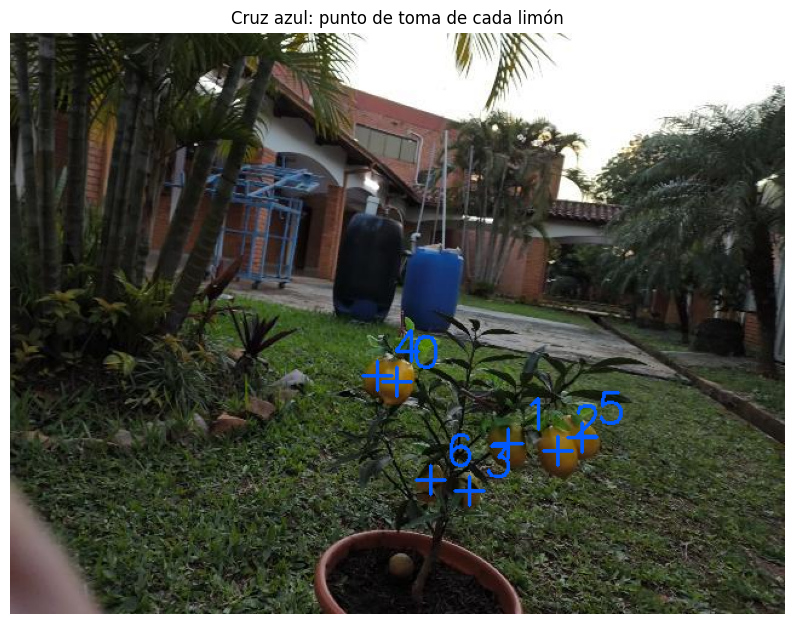

,conf,u_px,v_px,Z_cam_mm,toma_x_mm,toma_y_mm,toma_z_mm
0,0.87,319,288,658,837,-100,271
1,0.85,411,339,639,806,-218,212
2,0.85,452,345,608,776,-263,216
3,0.84,379,378,903,1045,-210,44
4,0.84,303,283,821,996,-72,236
5,0.83,472,334,731,895,-327,185
6,0.73,347,369,1006,1145,-156,15


In [19]:
# --------
# Parámetros supuestos (no medidos: reemplazar por los de la cámara real calibrada y medida sobre el robot)
# --------
FOV_H_GRADOS = 66.0        # [grados] campo de visión horizontal típico de la cámara principal de un celular
D_LIMON_M = 0.055          # [m] diámetro supuesto de un limón amarillo (medir los del limonero)
CAM_T = np.array([0.20, -0.10, 0.45])  # posición de la cámara en la base: tx, ty, h [m] (mástil adelante a la derecha)
CAM_PITCH_GRADOS = 10.0                # inclinación hacia abajo [grados]
CAM_YAW_GRADOS = 0.0                   # 0: mira hacia adelante [grados]


# --------
# Función que calcula la matriz de intrínsecos K a partir del campo de visión horizontal.
#   - Recibe: W y H (ancho y alto de la imagen en píxeles) y el FOV horizontal en grados.
#   - Devuelve: K, matriz 3 x 3 (píxeles cuadrados y centro óptico en el centro de la imagen).
# --------
def intrinsecos(W, H, fov_h_grados=FOV_H_GRADOS):
    fx = (W / 2) / math.tan(math.radians(fov_h_grados) / 2)
    return np.array([[fx, 0, W / 2],
                     [0, fx, H / 2],
                     [0,  0,     1]])


# --------
# Función que calcula la matriz homogénea 4 x 4 "base <- cámara" (igual que en la guía).
# --------
def transformacion_base_camara(t=CAM_T, pitch_grados=CAM_PITCH_GRADOS, yaw_grados=CAM_YAW_GRADOS):
    # R0: x cámara (derecha) -> -y robot; y cámara (abajo) -> -z robot; z cámara (adelante) -> +x robot.
    R0 = np.array([[0, 0, 1],
                   [-1, 0, 0],
                   [0, -1, 0]], dtype=float)
    th, ps = math.radians(pitch_grados), math.radians(yaw_grados)
    Ry = np.array([[math.cos(th), 0, math.sin(th)],
                   [0, 1, 0],
                   [-math.sin(th), 0, math.cos(th)]])
    Rz = np.array([[math.cos(ps), -math.sin(ps), 0],
                   [math.sin(ps), math.cos(ps), 0],
                   [0, 0, 1]])
    T = np.eye(4)
    T[:3, :3] = Rz @ Ry @ R0
    T[:3, 3] = t
    return T


T_BC = transformacion_base_camara()
np.set_printoptions(precision=3, suppress=True)
print("Transformación base <- cámara:\n", T_BC)


# --------
# Función de retroproyección: de píxel (u, v) y profundidad Z a punto (X, Y, Z) en la cámara.
# --------
def pixel_a_camara(u, v, Z, K):
    fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]
    return np.array([(u - cx) * Z / fx, (v - cy) * Z / fy, Z])


# --------
# Función que lleva un punto de la cámara a la base del robot (coordenadas homogéneas).
# --------
def camara_a_base(p_cam, T=T_BC):
    return (T @ np.append(p_cam, 1.0))[:3]


# --------
# Función que detecta limones en una imagen y estima su posición en el sistema del robot.
#   - Recibe: img_path (imagen), modelo (YOLO entrenado) y conf (confianza mínima).
#   - Devuelve: el resultado de YOLO y una tabla con una fila por limón.
# --------
def localizar_limones(img_path, modelo, conf=CONF_MIN):
    r = modelo.predict(source=img_path, conf=conf, imgsz=640, verbose=False)[0]
    H, W = r.orig_shape
    K = intrinsecos(W, H)
    filas = []
    for (x1, y1, x2, y2), cf in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()):
        # Punto de toma: centro de la caja.
        u, v = (x1 + x2) / 2, (y1 + y2) / 2
        # Profundidad por tamaño conocido. Usamos el lado MAYOR de la caja: si una hoja tapa medio limón,
        # suele achicarse un solo lado.
        Z = K[0, 0] * D_LIMON_M / max(x2 - x1, y2 - y1)
        p = camara_a_base(pixel_a_camara(u, v, Z, K))
        filas.append({"conf": round(float(cf), 2), "u_px": int(u), "v_px": int(v), "Z_cam_mm": round(Z * 1000),
                      "toma_x_mm": round(p[0] * 1000), "toma_y_mm": round(p[1] * 1000), "toma_z_mm": round(p[2] * 1000)})
    return r, pd.DataFrame(filas, columns=["conf", "u_px", "v_px", "Z_cam_mm", "toma_x_mm", "toma_y_mm", "toma_z_mm"])


# --------
# Función que dibuja el punto de toma y el número de fila de cada limón.
# --------
def dibujar_localizacion(r, tabla):
    img = cv2.cvtColor(r.orig_img.copy(), cv2.COLOR_BGR2RGB)
    esp = max(2, img.shape[1] // 400)
    for i, f in tabla.iterrows():
        pt = (int(f.u_px), int(f.v_px))
        cv2.drawMarker(img, pt, AZUL, cv2.MARKER_CROSS, 12 * esp, esp)
        cv2.putText(img, str(i), (pt[0] + 6 * esp, pt[1] - 6 * esp), cv2.FONT_HERSHEY_SIMPLEX, 0.6 * esp, AZUL, esp)
    return img


# Localizamos los limones de una foto propia de validación.
r, tabla_loc = localizar_limones(muestras[0], model_trained)
plt.figure(figsize=(10, 8))
plt.imshow(dibujar_localizacion(r, tabla_loc))
plt.title("Cruz azul: punto de toma de cada limón")
plt.axis("off")
plt.show()
tabla_loc

### **9.4 Selección del objetivo**

Criterio de nuestro robot:

1. Solo limones con confianza suficiente.
2. Entre ellos, el más cercano a la cámara (menor $Z$): menos oclusión y menor recorrido del brazo.

En ROS 2 la salida es un `geometry_msgs/PointStamped` con `frame_id = "base_link"` hacia la cinemática inversa.

In [20]:
CONF_COSECHA = 0.50
candidatos = tabla_loc[tabla_loc.conf >= CONF_COSECHA]
if candidatos.empty:
    print("No hay limones con confianza suficiente: reposicionar el robot.")
else:
    objetivo = candidatos.sort_values("Z_cam_mm").iloc[0]
    print(f"Objetivo: limón {objetivo.name}  (conf = {objetivo.conf})")
    print(f"  Punto de toma [mm, base del robot]: x = {objetivo.toma_x_mm}, y = {objetivo.toma_y_mm}, z = {objetivo.toma_z_mm}")

Objetivo: limón 2  (conf = 0.85)
  Punto de toma [mm, base del robot]: x = 776.0, y = -263.0, z = 216.0


**Análisis.** La imagen muestra el punto de toma de cada limón y la tabla, sus coordenadas en el sistema del robot; el objetivo elegido es el más cercano con confianza suficiente. Los valores (limones entre 0,6 y 1 m) son razonables pero ilustrativos, porque la cámara del celular no está calibrada.

## **10. ¿Qué tan buena es la estimación monocular? Comparación con estéreo**

Con tamaño conocido, $\Delta Z / Z = \Delta D / D$: el error relativo en la distancia es igual al error relativo
en el diámetro supuesto. Los limones del mismo árbol varían fácilmente entre 45 y 65 mm.

Con estéreo (lo que usa nuestro robot), $Z = f_x B / d_{disp}$ y el error por un error de disparidad
$\Delta d$ es:

$$\Delta Z \approx \frac{Z^2}{f_x\, B}\, \Delta d$$

Para las cámaras NoIR a 640 px de ancho ($\mathrm{FOV}_h = 62{,}2°$, $f_x \approx 530$ px), $B = 90$ mm y un
error de disparidad de 0,5 px. La celda compara ambos contra el requisito B5: error de localización
≤ 35 mm.

In [21]:
diametros_reales_mm = [45, 50, 55, 60, 65]
distancias_m = [0.3, 0.5, 0.8]
FX_NOIR, B_ESTEREO, DELTA_DISP = 320 / math.tan(math.radians(62.2 / 2)), 0.090, 0.5

filas = []
for D_real in diametros_reales_mm:
    fila = {"método": f"monocular, limón de {D_real} mm"}
    for Zr in distancias_m:
        fila[f"error en Z a {Zr} m [mm]"] = round((Zr * D_LIMON_M / (D_real / 1000) - Zr) * 1000)
    filas.append(fila)
fila = {"método": f"estéreo B = 90 mm, ±{DELTA_DISP} px"}
for Zr in distancias_m:
    fila[f"error en Z a {Zr} m [mm]"] = round(Zr ** 2 / (FX_NOIR * B_ESTEREO) * DELTA_DISP * 1000)
filas.append(fila)
pd.DataFrame(filas)

,método,error en Z a 0.3 m [mm],error en Z a 0.5 m [mm],error en Z a 0.8 m [mm]
0,"monocular, limón de 45 mm",67,111,178
1,"monocular, limón de 50 mm",30,50,80
2,"monocular, limón de 55 mm",0,0,0
3,"monocular, limón de 60 mm",-25,-42,-67
4,"monocular, limón de 65 mm",-46,-77,-123
5,"estéreo B = 90 mm, ±0.5 px",1,3,7


**Análisis.** La tabla muestra por qué el robot usa dos cámaras: con una sola, un limón de 45 mm en vez de los 55 mm supuestos da 111 mm de error a 0,5 m, tres veces lo que admite B5 (≤ 35 mm); con estéreo el error es de unos 3 mm y no depende del tamaño del limón. Por eso YOLO (este cuaderno) da el (u, v) del limón y el estéreo, su Z.

## **11. Probar con una imagen propia**

Subir una foto nueva (por ejemplo, sacada con la cámara del robot) y ver qué detecta el modelo. Si el fondo, la
iluminación o la cámara son distintos a los del entrenamiento, se espera que funcione peor: eso indica que hay
que sumar esas imágenes etiquetadas al proyecto de Roboflow y reentrenar.

In [22]:
from google.colab import files

subidos = files.upload()
for nombre in subidos:
    r_prop, tabla_prop = localizar_limones(nombre, model_trained)
    plt.figure(figsize=(12, 9))
    plt.imshow(dibujar_localizacion(r_prop, tabla_prop))
    plt.title(nombre)
    plt.axis("off")
    plt.show()
    display(tabla_prop)

**Análisis.** Son 8 fotos de otro día y otro lugar, que el modelo nunca vio. Encontró los limones visibles y no marcó las hojas amarillas del fondo; repitió el problema de algún limón marcado dos veces.

## **12. Conclusión**

Resumen de las cifras principales (cada resultado está analizado debajo de su celda).

In [23]:
print("== Datasets ==")
display(estadisticas)
print("== Evaluación ==")
display(tabla)
print("== Velocidad ==")
display(velocidad)
print("Épocas entrenadas:", len(pd.read_csv(os.path.join(save_dir, "results.csv"))), "de", EPOCHS)

== Datasets ==


,dataset,conjunto,imágenes,limones,imágenes descartadas
0,base,train,668,963,1452
1,base,valid,227,316,499
2,base,test,20,36,38
3,propio,train,90,175,0
4,propio,valid,10,58,0
5,propio,test,10,58,0


== Evaluación ==


,conjunto,imágenes,precisión,recobrado,mAP50,mAP50-95
0,propio_20,20,0.929,0.922,0.952,0.746
1,propio_test,10,0.960,0.862,0.938,0.723
2,base_valid,227,0.780,0.769,0.843,0.554


== Velocidad ==


,imgsz,recobrado,mAP50,ms por imagen (CPU Colab)
0,640,0.922,0.952,86
1,480,0.907,0.962,57
2,320,0.853,0.892,34


Épocas entrenadas: 51 de 60


**Conclusión.** El modelo cumple la tarea: con la base de datos propia (20 fotos) detecta los limones amarillos con P = 0,93 y R = 0,92 (criterio B4 cumplido), no confunde la naranja ni las hojas con limones y, a 480 px, es lo bastante liviano y rápido para la Raspberry Pi 5.

**Mejoras posibles.**

- Limones duplicados: agregar un filtro de cajas superpuestas (NMS) al predecir, o probar yolo11n, que lo trae.
- Dataset base incompleto: reemplazarlo por uno mejor etiquetado, o sacar las fotos donde el modelo detecta muchos más limones que los marcados.
- Métricas algo optimistas: las 50 fotos son del mismo árbol y se sacaron con segundos de diferencia, así que fotos casi iguales quedan en train y en validación. Una prueba más exigente es usar como test fotos de otro día, etiquetadas.
- Cámara del robot: las fotos son de celular y el robot usa cámaras NoIR (al sol los colores salen lavados). Hay que sumar fotos de esas cámaras al proyecto de Roboflow y reentrenar.
- Medir en la Pi 5 el tiempo real del modelo NCNN.

**Referencias.**

- Brunetti Fernández, F. J. (2026). Visión Artificial e IA: Robot Recolector de Frutillas con YOLO (versión R2_TPF2026S2_v2) [Cuaderno de Google Colab]. Robótica 2, Facultad de Ingeniería, Universidad Nacional de Asunción.
- brinjalproject (s. f.). lemons-segmentation (versión 5) [Dataset]. Roboflow Universe. https://universe.roboflow.com/brinjalproject/lemons-segmentation
- Grupo 2, Robótica 2 FIUNA (2026). limones-amarillos (versión 3) [Dataset]. Roboflow Universe. Licencia CC BY 4.0. https://universe.roboflow.com/hectors-workspace-e5dhh/limones-amarillos
- Jocher, G. y Qiu, J. (2026). Ultralytics YOLO26 (versión 8.4.153) [Software]. Licencia AGPL-3.0. https://github.com/ultralytics/ultralytics
- Roboflow (2026). Roboflow: plataforma de etiquetado y gestión de datasets [Software]. https://roboflow.com
- Tencent (2026). NCNN: framework de inferencia de redes neuronales para dispositivos móviles [Software]. https://github.com/Tencent/ncnn